In [1]:
import pandas as pd
import numpy as np
import pickle
import glob
from scipy.stats import norm
from scipy.stats import gaussian_kde
import os

import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
from scipy.stats import gaussian_kde

import matplotlib as mpl
matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'
# import scipy.io as sio

In [33]:
def half_fft(y, t = None, dt = None):
    """
    Compute the one-sided FFT of a signal.

    Parameters:
        y (numpy.ndarray): The input signal in time domain.
        t (numpy.ndarray, optional): The time array corresponding to the signal. If not provided, `dt` must be specified.
        dt (float, optional): The time step (1/sample rate). If not provided, it will be calculated from `t`.

    Returns:
        tuple: A tuple containing:
            - y_fft (numpy.ndarray): The one-sided FFT of the input signal.
            - freq (numpy.ndarray): The corresponding frequency array.

    Notes:
        - If both `t` and `dt` are not provided, the function will return `None` and print an error message.
        - The FFT is normalized using the 'forward' norm, and the amplitudes are doubled for non-DC components.
    """
    
    if dt is None:
        try:
            dt = np.mean(np.diff(t))
        except:
            print('You must either provide an array of times or a dt (1/sample rate).')
            return None
    
    y_fft = np.fft.fft(y, norm = 'forward')
    freq = np.fft.fftfreq(len(y_fft), dt)

    fidx = freq>=0
    freq=freq[fidx]
    y_fft = y_fft[fidx]
    y_fft = np.abs(y_fft)
    y_fft[1:]*=2
    
    return y_fft, freq

In [2]:
# input all parameters
Fs = 3e4
TimeHistory = 20e-3 # in seconds
TimePost = 2e-3 # in seconds
Num_Repeats = 30

In [20]:
filepath_model = glob.glob('./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/*.pickle')
filepath_degrees = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_degrees.pickle')
filepath_notdegrees = glob.glob('./dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/*_scaled.pickle')

out_path = './dataFolder/Figures/3_1DCompModel/STAFeatures/'
os.makedirs(out_path, exist_ok=True)

In [21]:
# instead of going through all data, make list of moth and unit IDs that you want to run this analysis for

moth_unit = [('m23', 'unit_1'),
             ('m29', 'unit_1'),
             ('m30', 'unit_1'),
             ('m31', 'unit_1'),
             ('m31', 'unit_2'),
             ('m31', 'unit_3')]

In [22]:
filepath = [f for f in filepath_model if name + '_' + unitID in f][0]

processing m23 and unit_1
processing m29 and unit_1
processing m30 and unit_1
processing m31 and unit_1
processing m31 and unit_2
processing m31 and unit_3


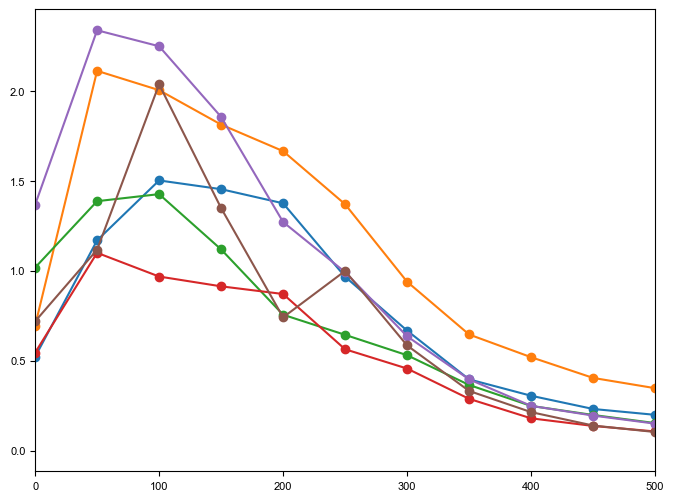

In [57]:
# read in all the data

fig_fft, ax_fft = plt.subplots(figsize=(8, 6))

for name, unitID in moth_unit:
    print(f'processing {name} and {unitID}')
    
    ########## get the correct timestamp files depending on whether we have degree or not #########################
    filename = [f for f in filepath_degrees if name in f]
    if not filename:
        filename = [f for f in filepath_notdegrees if name in f][0]
        with open(filename, "rb") as f:
            testout = pickle.load(f)
        WhiteNoise = testout[2]
        
    else:
        with open(filename[0], "rb") as f:
            testout = pickle.load(f)
        WhiteNoise = testout[2]

    
    ########## get the data files #########################  
    filename = [f for f in filepath_model if name + '_' + unitID in f][0]
    with open(filename, 'rb') as f:
                savedModel = pickle.load(f)
    
#     ste = savedModel[0]
    sta = savedModel[1]
    sta_error = savedModel[2]
#     prior_ensemble = savedModel[3]
#     prior_mean = savedModel[4]
#     prior_error = savedModel[5]
#     prior_std = savedModel[6]
#     mean_fire_rate = savedModel[7]
#     nld = savedModel[8]
#     n_ste = savedModel[9]
#     n_prior = savedModel[10]
#     bin_centers = savedModel[11]
#     bin_centers_fwdModel = savedModel[12]
#     nld_fwdModel = savedModel[13]
    
    ######## fft of STA #################################

    fft, freq = half_fft(y = sta[:-int(TimePost*Fs)], dt = 1/Fs)
    
    ######## plot fft ####################################
    ax_fft.plot(freq, fft, 'o-')
    ax_fft.set_xlim(0,500)
#     filename = out_path + name + '_' + unitID + '_STA.pdf'
#     fig_sta.savefig(filename)
#     ax_sta.cla()


In [116]:
fft_sta, freq_sta = half_fft(y = sta, dt = 1/Fs)

from scipy.signal import resample
WhiteNoise_down = resample(WhiteNoise, len(sta))

fft, freq = half_fft(y = WhiteNoise, dt = 1/Fs)
fft_down, freq_down = half_fft(y = WhiteNoise_down, dt = 1/Fs)

from scipy.signal import savgol_filter
fft_smoothened = savgol_filter(fft, window_length=301, polyorder=3)

(0.0, 500.0)

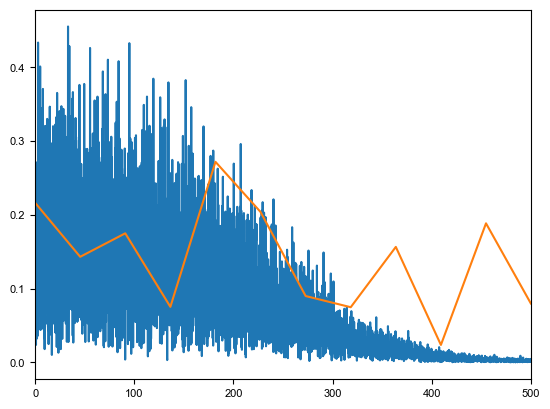

In [117]:
plt.plot(freq, fft)
plt.plot(freq_down, fft_down)
plt.xlim(0,500)
# plt.plot(freq, fft_smoothened)

(0.0, 800.0)

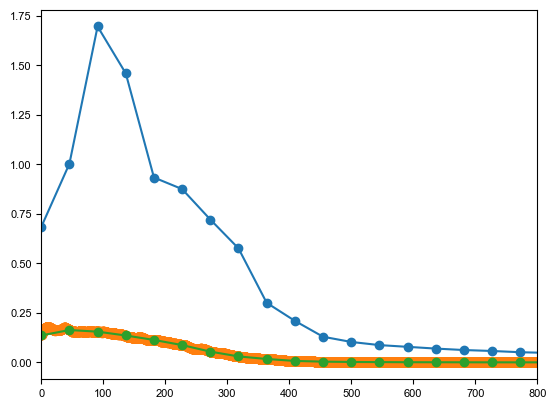

In [130]:
plt.plot(freq_sta, fft_sta, 'o-')
plt.plot(freq, fft_smoothened, 'o-')

from scipy.interpolate import interp1d
interp_func = interp1d(freq, fft_smoothened, kind='linear', fill_value="extrapolate")
fft_matched = interp_func(freq_sta)
plt.plot(freq_sta, fft_matched, 'o-')

plt.xlim(0,800)
# plt.plot(freq, fft_sta[1:]/fft_smoothened)

In [124]:
len(fft_sta), len(fft_matched)

(330, 330)

(0.0, 500.0)

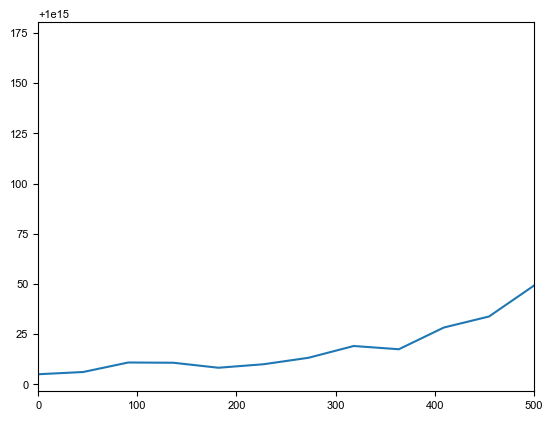

In [133]:
fft_sta_whitened = fft_sta[:18]/fft_matched[:18]
plt.plot(freq_sta[:18], fft_sta_whitened)
plt.xlim(0,500)

In [95]:
len(fft_smoothened)

150001

In [105]:
len(WhiteNoise)

300003

In [106]:
len(sta)

660

##### using covariance of stimulus to get whitened STA

In [147]:
def make_design_matrix(stim, L):
    """
    stim: (T,)
    L: number of lags
    
    returns: (T-L+1, L)
    """
    T = len(stim)
    T_eff = T - L + 1
    
    X = np.zeros((T_eff, L))
    
    for i in range(L):
        X[:, i] = stim[i : i + T_eff]
    
    return X

In [135]:
def compute_Cp(stim, L, reg=1e-6):
    """
    stim: (T,) white noise stimulus
    L: STA length
    
    returns: Cp (L x L)
    """
    X = make_design_matrix(stim, L)
    
    # zero-mean (important even for "white noise")
    X = X - np.mean(X, axis=0, keepdims=True)
    
    T_eff = X.shape[0]
    
    Cp = (X.T @ X) / T_eff
    
    # regularization (very important)
    Cp += reg * np.eye(L)
    
    return Cp

In [134]:
def whiten_sta_symmetric(Cp, STA_raw):
    eigvals, eigvecs = np.linalg.eigh(Cp)
    
    D_inv_sqrt = np.diag(1.0 / np.sqrt(eigvals))
    Cp_inv_sqrt = eigvecs @ D_inv_sqrt @ eigvecs.T
    
    return Cp_inv_sqrt @ STA_raw

In [148]:
def compute_whitened_sta(stim, STA_raw):
    L = len(STA_raw)
    
    Cp = compute_Cp(stim, L)
    
    STA_white = whiten_sta_symmetric(Cp, STA_raw)
    
    return STA_white

In [150]:
STA_white = compute_whitened_sta(WhiteNoise, sta)

C:\Users\tanvi.deora\AppData\Local\Temp\ipykernel_41980\443833367.py:14: FutureWarning: The behavior of obj[i:j] with a float-dtype index is deprecated. In a future version, this will be treated as positional instead of label-based. For label-based slicing, use obj.loc[i:j] instead
  X[:, i] = stim[i : i + T_eff]


ValueError: could not broadcast input array from shape (300003,) into shape (299344,)

In [154]:
L = len(sta)
T = len(WhiteNoise)
T_eff = T - L + 1

X = np.zeros((T_eff, L))

for i in range(L):
    start = i
    end = T_eff + i
    length = end - start
    print(length)
    X[:, i] = WhiteNoise[i : i + T_eff]

MemoryError: Unable to allocate 1.47 GiB for an array with shape (299344, 660) and data type float64

In [155]:
from scipy.linalg import toeplitz

def compute_Cp_fast(stim, L):
    stim = stim - np.mean(stim)
    T = len(stim)
    
    acf = np.correlate(stim, stim, mode='full') / T
    mid = len(acf) // 2
    
    r = acf[mid:mid+L]
    
    return toeplitz(r)

In [156]:
Cp = compute_Cp_fast(WhiteNoise, len(sta))
STA_white = whiten_sta_symmetric(Cp, sta)

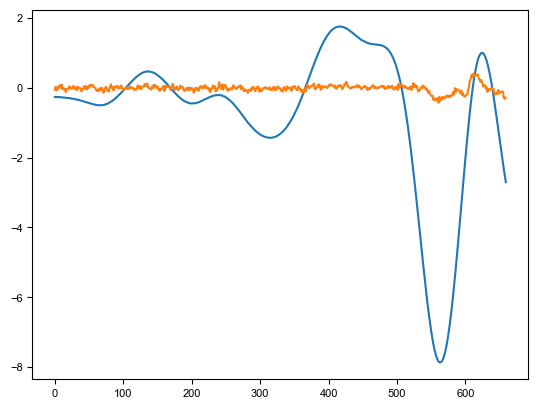

In [160]:
plt.plot(sta)
plt.plot(STA_white)